This notebook continues the network analysis performed in Part1_analysis.ipynb and Part2_analysis.ipynb. It addresses the optional task 2.3 of the README: *modeling recommendations based on the similar viewer approach versus the movie similarity approach, using infection-based modeling.*

# imports

In [17]:
import zipfile
from dataclasses import dataclass
from os import getcwd
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix

# Settings

In [18]:
SEED = 42

# Network construction (identical to the setup notebook)
DENSITY = 15
POSITIVE_THRESHOLD = 3.5
MIN_SHARED_POSITIVE = 100

# User split
EVAL_MIN_RATINGS = 30
N_EVAL_USERS = 6000
VALIDATION_FRACTION = 0.3
HISTORY_FRACTION = 0.8
MIN_SEEDS = 5
MIN_TARGETS = 3
MIN_CANDIDATES = 50

# Evaluation
KS = [10, 20]
PRIMARY_K = 10

# Infection model search space
BETAS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
WEIGHTINGS = [False, True]   # False: p = beta; True: p = beta * w / mean(w)
T_MAX = 5
TUNE_RUNS = 10
TEST_RUNS = 50

# Loading data

## Networks and movie metadata from the setup notebook

In [3]:
print(getcwd())

c:\Users\alpet\Desktop\TU Delft\Modeling and Data Analysis\analysis-labs\project\Notebook user vs genome


In [4]:
DATA_DIR = Path(getcwd()) / "movie_networks"  # Change if needed

nodes_df = pd.read_csv(DATA_DIR / "nodes.csv")

movie_ids = np.sort(nodes_df["movieId"].to_numpy())
N_MOVIES = len(movie_ids)
movie_titles = nodes_df.set_index("movieId").loc[movie_ids, "title"].to_numpy()

if len(set(movie_ids)) != N_MOVIES:
    raise ValueError("nodes.csv must contain one row per movie.")


def load_saved_graph(network_type, density_pct):
    G = nx.read_graphml(DATA_DIR / f"{network_type}_{density_pct}pct.graphml")

    if G.is_directed() or G.is_multigraph() or nx.number_of_selfloops(G) > 0:
        raise ValueError("Expected a simple undirected graph without self-loops.")

    # GraphML stores node IDs as strings.
    return nx.relabel_nodes(G, int)


def weight_matrix(G):
    """Symmetric N x N matrix of similarity weights (0 = no edge), rows ordered by movieId."""
    position = {movie_id: i for i, movie_id in enumerate(movie_ids)}
    W = np.zeros((N_MOVIES, N_MOVIES), dtype=np.float64)

    for u, v, weight in G.edges(data="weight"):
        i, j = position[u], position[v]
        W[i, j] = W[j, i] = weight

    return W


W_genome = weight_matrix(load_saved_graph("genome", DENSITY))
N_EDGES = int((W_genome > 0).sum() // 2)

print(f"Movies: {N_MOVIES:,}")
print(f"Genome network at {DENSITY}% density: {N_EDGES:,} edges")

Movies: 500
Genome network at 15% density: 18,713 edges


## Ratings of the 500 movies

In [8]:
PROJECT_DIR = Path(getcwd()).parent
RATINGS_CANDIDATES = [
    PROJECT_DIR / "data" / "ml-latest" / "ratings.csv",
    PROJECT_DIR / "data" / "ml_latest" / "ratings.csv",
]
ZIP_PATH = PROJECT_DIR / "data" / "ml-latest.zip"


def open_ratings():
    for path in RATINGS_CANDIDATES:
        if path.exists():
            return open(path, "rb")

    # A Git LFS pointer is only ~130 bytes: it must be pulled before use.
    if ZIP_PATH.exists() and ZIP_PATH.stat().st_size > 10**6:
        archive = zipfile.ZipFile(ZIP_PATH)
        member = next(name for name in archive.namelist() if name.endswith("ratings.csv"))
        return archive.open(member)

    raise FileNotFoundError(
        "ratings.csv not found. Extract ml-latest into project/data/ml-latest "
        "(or run `git lfs pull` to fetch ml-latest.zip)."
    )


chunks = []

with open_ratings() as file:
    for chunk in pd.read_csv(
        file,
        usecols=["userId", "movieId", "rating", "timestamp"],
        dtype={"userId": np.int32, "movieId": np.int32, "rating": np.float32, "timestamp": np.int64},
        chunksize=5_000_000,
    ):
        chunks.append(chunk[chunk["movieId"].isin(movie_ids)])

ratings = pd.concat(chunks, ignore_index=True)
del chunks

# Position of each movie in the (sorted) movie list, shared by every matrix below.
ratings["movie_pos"] = np.searchsorted(movie_ids, ratings["movieId"].to_numpy())

if not np.array_equal(movie_ids[ratings["movie_pos"].to_numpy()], ratings["movieId"].to_numpy()):
    raise ValueError("Some rated movies are missing from nodes.csv.")

if ratings.duplicated(["userId", "movieId"]).any():
    raise ValueError("Duplicate user–movie pairs found.")

print(f"Ratings of the {N_MOVIES} movies: {len(ratings):,}")
print(f"Users: {ratings['userId'].nunique():,}")

Ratings of the 500 movies: 14,516,319
Users: 309,286


# Splitting users and time

## Network users versus evaluation users

In [9]:
rng = np.random.default_rng(SEED)

user_counts = ratings.groupby("userId").size()
eligible_users = user_counts.index[user_counts >= EVAL_MIN_RATINGS].to_numpy()

n_sampled = min(N_EVAL_USERS, len(eligible_users))
sampled_users = rng.choice(eligible_users, size=n_sampled, replace=False)

is_eval_user = ratings["userId"].isin(sampled_users).to_numpy()

# Only these ratings may be used to build the audience network.
network_ratings = ratings.loc[~is_eval_user]
eval_ratings = (
    ratings.loc[is_eval_user]
    .sort_values(["userId", "timestamp", "movieId"])
    .reset_index(drop=True)
)

print(f"Users with at least {EVAL_MIN_RATINGS} ratings: {len(eligible_users):,}")
print(f"Sampled evaluation users: {n_sampled:,}")
print(f"Network users: {network_ratings['userId'].nunique():,} "
      f"({len(network_ratings):,} ratings)")

Users with at least 30 ratings: 131,210
Sampled evaluation users: 6,000
Network users: 303,286 (13,936,036 ratings)


## History and held-out future for each evaluation user

Many users rate large batches of movies within the same second, so the order within such a batch is arbitrary (we break ties by movie ID). The split is therefore time-respecting between sessions, but not within one.

In [10]:
grouped = eval_ratings.groupby("userId")
position_in_timeline = grouped.cumcount().to_numpy()
timeline_length = grouped["movieId"].transform("size").to_numpy()

in_history = position_in_timeline < np.ceil(HISTORY_FRACTION * timeline_length)
is_positive = eval_ratings["rating"].to_numpy() >= POSITIVE_THRESHOLD

all_eval_users = np.sort(eval_ratings["userId"].unique())
user_row = np.searchsorted(all_eval_users, eval_ratings["userId"].to_numpy())
movie_col = eval_ratings["movie_pos"].to_numpy()


def indicator(mask):
    M = np.zeros((len(all_eval_users), N_MOVIES), dtype=bool)
    M[user_row[mask], movie_col[mask]] = True
    return M


seed_matrix = indicator(in_history & is_positive)    # liked in the history -> infected at t = 0
seen_matrix = indicator(in_history)                  # rated in the history -> never recommended
target_matrix = indicator(~in_history & is_positive) # liked in the future  -> what we try to predict

keep = (
    (seed_matrix.sum(axis=1) >= MIN_SEEDS)
    & (target_matrix.sum(axis=1) >= MIN_TARGETS)
    & ((~seen_matrix).sum(axis=1) >= MIN_CANDIDATES)
)

print(f"Evaluation users kept: {keep.sum():,} of {len(keep):,}")


@dataclass
class EvalSet:
    user_ids: np.ndarray
    seeds: np.ndarray
    seen: np.ndarray
    targets: np.ndarray

    def subset(self, index):
        return EvalSet(
            self.user_ids[index], self.seeds[index], self.seen[index], self.targets[index]
        )


full_eval = EvalSet(
    all_eval_users[keep], seed_matrix[keep], seen_matrix[keep], target_matrix[keep]
)

permutation = rng.permutation(len(full_eval.user_ids))
n_validation = int(round(VALIDATION_FRACTION * len(permutation)))

eval_sets = {
    "validation": full_eval.subset(np.sort(permutation[:n_validation])),
    "test": full_eval.subset(np.sort(permutation[n_validation:])),
}

split_summary = pd.DataFrame({
    name: {
        "users": len(es.user_ids),
        "mean seeds per user": es.seeds.sum(axis=1).mean(),
        "mean held-out positives per user": es.targets.sum(axis=1).mean(),
        "mean candidate movies per user": (~es.seen).sum(axis=1).mean(),
    }
    for name, es in eval_sets.items()
}).T

display(split_summary.round(2))

Evaluation users kept: 5,724 of 6,000


,users,mean seeds per user,mean held-out positives per user,mean candidate movies per user
validation,1717.0,57.15,13.38,420.58
test,4007.0,57.13,13.35,420.60


# Audience network without the evaluation users

## Rebuilding the user network from network users only

This follows the construction of the setup notebook, on the network users only. The number of edges is matched to the genome network so that both networks have the same density.

In [11]:
network_positive = network_ratings.loc[network_ratings["rating"] >= POSITIVE_THRESHOLD]
network_positive_counts = np.bincount(network_positive["movie_pos"], minlength=N_MOVIES)


def build_audience_matrix(n_edges, min_shared=MIN_SHARED_POSITIVE):
    """Positive-only cosine similarity between the audiences of two movies (network users only)."""
    user_codes, user_position = np.unique(network_positive["userId"].to_numpy(), return_inverse=True)

    B = csr_matrix(
        (
            np.ones(len(network_positive)),
            (network_positive["movie_pos"].to_numpy(), user_position),
        ),
        shape=(N_MOVIES, len(user_codes)),
    )

    shared = (B @ B.T).toarray()
    counts = np.asarray(B.sum(axis=1)).ravel()
    denominator = np.sqrt(np.outer(counts, counts))
    similarity = np.divide(shared, denominator, out=np.zeros_like(shared), where=denominator > 0)

    i, j = np.triu_indices(N_MOVIES, k=1)
    candidates = pd.DataFrame({
        "i": i, "j": j, "weight": similarity[i, j], "shared": shared[i, j],
    })
    candidates = candidates.loc[
        (candidates["weight"] > 0) & (candidates["shared"] >= min_shared)
    ]

    if len(candidates) < n_edges:
        raise ValueError(
            f"Only {len(candidates):,} eligible edges, but {n_edges:,} are required."
        )

    # Strongest edges first, with the same deterministic tie-breaking as the setup notebook.
    chosen = candidates.sort_values(
        ["weight", "i", "j"], ascending=[False, True, True]
    ).head(n_edges)

    W = np.zeros((N_MOVIES, N_MOVIES), dtype=np.float64)
    W[chosen["i"], chosen["j"]] = chosen["weight"]
    W[chosen["j"], chosen["i"]] = chosen["weight"]
    return W


W_user = build_audience_matrix(N_EDGES)

## Sanity checks

We compare the rebuilt audience network with the one saved by the setup notebook, and summarise both networks. A high Jaccard similarity shows that removing the evaluation users hardly changes the audience network, so that the comparison remains faithful to the earlier analysis.

In [12]:
W_user_saved = weight_matrix(load_saved_graph("user", DENSITY))


def upper_edges(W):
    return np.triu(W > 0, k=1)


a, b = upper_edges(W_user), upper_edges(W_user_saved)
print(f"Edge Jaccard similarity, rebuilt vs saved user network: {(a & b).sum() / (a | b).sum():.3f}")

g = upper_edges(W_genome)
print(f"Edge Jaccard similarity, genome vs rebuilt user network: {(g & a).sum() / (g | a).sum():.3f}")

network_summary = pd.DataFrame({
    name: {
        "edges": int(upper_edges(W).sum()),
        "isolated movies": int(((W > 0).sum(axis=1) == 0).sum()),
        "mean degree": (W > 0).sum(axis=1).mean(),
        "mean edge weight": W[W > 0].mean(),
    }
    for name, W in [("genome", W_genome), ("user (rebuilt)", W_user), ("user (saved)", W_user_saved)]
}).T

display(network_summary.round(4))

NETWORK_MATRICES = {
    "Genome": [W_genome],
    "Audience": [W_user],
    "Hybrid": [W_genome, W_user],  # two independent transmission channels
}

Edge Jaccard similarity, rebuilt vs saved user network: 0.992
Edge Jaccard similarity, genome vs rebuilt user network: 0.298


,edges,isolated movies,mean degree,mean edge weight
genome,18713.0,0.0,74.852,0.7935
user (rebuilt),18713.0,27.0,74.852,0.3328
user (saved),18713.0,28.0,74.852,0.3343


# The infection model

## Transmission and simulation

Because a susceptible movie is infected by each infected neighbour independently, the probability that it escapes all of them is $\exp(-\sum_i \lambda_{ij})$ with $\lambda_{ij} = -\ln(1 - p_{ij})$. One time step for **all** users and **all** runs is then a single matrix product (infected state times the matrix of $\lambda$ values), which makes it feasible to simulate thousands of users with many stochastic runs. Two networks used together (hybrid) simply add their $\lambda$ matrices.

In [13]:
def exposure_matrix(W, beta, weighted):
    """lambda_ij = -ln(1 - p_ij) for the edges of W; zero elsewhere."""
    edges = W > 0

    if weighted:
        P = np.clip(beta * W / W[edges].mean(), 0.0, 0.99)
    else:
        P = np.where(edges, beta, 0.0)

    return -np.log1p(-P)


def make_exposure(matrices, beta, weighted):
    return sum(exposure_matrix(W, beta, weighted) for W in matrices).astype(np.float32)


def simulate_si(exposure, seeds, t_max, n_runs, rng, batch_size=250):
    """
    Discrete-time SI process started from the seed movies of every user.

    Returns
    -------
    scores : (t_max, users, movies) array
        scores[T-1] is the infection score for horizon T: the fraction of steps 1..T at which
        each movie was infected, averaged over the runs.
    infected : (t_max, users) array
        Average number of infected movies (seeds included) after each step.
    """
    n_users, n_movies = seeds.shape
    scores = np.zeros((t_max, n_users, n_movies), dtype=np.float32)
    infected = np.zeros((t_max, n_users), dtype=np.float32)

    for start in range(0, n_users, batch_size):
        batch = slice(start, min(start + batch_size, n_users))
        size = batch.stop - batch.start

        # Rows are ordered (run, user), so reshape(n_runs, size, ...) recovers them.
        state = np.tile(seeds[batch], (n_runs, 1))
        time_integral = np.zeros(state.shape, dtype=np.float32)

        for t in range(t_max):
            exposure_now = state.astype(np.float32) @ exposure
            p_infection = -np.expm1(-exposure_now)

            # Probability of being infected at this step given the previous state. Averaging this
            # instead of the sampled 0/1 outcome has the same expectation but far less noise,
            # which matters when beta is small and most movies are rarely infected.
            time_integral += np.where(state, 1.0, p_infection)

            state |= (rng.random(p_infection.shape, dtype=np.float32) < p_infection)

            scores[t, batch] = time_integral.reshape(n_runs, size, n_movies).mean(axis=0) / (t + 1)
            infected[t, batch] = state.reshape(n_runs, size, n_movies).sum(axis=2).mean(axis=0)

    return scores, infected

# Metrics and baselines

## Ranking and accuracy metrics

For every user, the unseen movies are ranked by score and the top $K$ are evaluated against the held-out positive ratings (the *targets*): precision, recall, hit rate (at least one target in the list) and NDCG. Exact ties (for example, movies that were never infected) are broken at random, with the same random numbers for every method.

In [14]:
def rank_top_k(scores, seen, k, seed=SEED):
    jitter = np.random.default_rng(seed).random(scores.shape)
    s = scores.astype(np.float64) + 1e-9 * jitter
    s[seen] = -np.inf

    top = np.argpartition(-s, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(s, top, axis=1), axis=1)
    return np.take_along_axis(top, order, axis=1)


def user_metrics(top, targets, k):
    top = top[:, :k]
    hits = np.take_along_axis(targets, top, axis=1)
    n_relevant = targets.sum(axis=1)

    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    ideal = np.cumsum(discounts)[np.minimum(n_relevant, k) - 1]

    return pd.DataFrame({
        "precision": hits.sum(axis=1) / k,
        "recall": hits.sum(axis=1) / n_relevant,
        "hit_rate": hits.any(axis=1).astype(float),
        "ndcg": (hits * discounts).sum(axis=1) / ideal,
    })


def bootstrap_ci(values, n_boot=2000, seed=SEED):
    """95% bootstrap interval of the mean, resampling users."""
    values = np.asarray(values, dtype=float)
    index = np.random.default_rng(seed).integers(0, len(values), size=(n_boot, len(values)))
    return tuple(np.percentile(values[index].mean(axis=1), [2.5, 97.5]))

## Tuning the infection parameters on the validation users

For every network, we search the transmission probability $\beta$, the horizon $T$ and the weighting. The selection criterion is NDCG@10 on the **validation** users; the test users are not touched here.

In [20]:
def tune_network(matrices, eval_set, betas=BETAS, weightings=WEIGHTINGS,
                 t_max=T_MAX, n_runs=TUNE_RUNS, k=PRIMARY_K, seed=SEED):
    rows = []

    for weighted in weightings:
        for beta in betas:
            rng = np.random.default_rng(seed)
            exposure = make_exposure(matrices, beta, weighted)
            scores, _ = simulate_si(exposure, eval_set.seeds, t_max, n_runs, rng)

            for t in range(t_max):
                top = rank_top_k(scores[t], eval_set.seen, k)
                metrics = user_metrics(top, eval_set.targets, k)
                rows.append({
                    "weighted": weighted,
                    "beta": beta,
                    "T": t + 1,
                    "ndcg": metrics["ndcg"].mean(),
                    "recall": metrics["recall"].mean(),
                })

    return pd.DataFrame(rows)


tuning = pd.concat(
    {name: tune_network(matrices, eval_sets["validation"]) for name, matrices in NETWORK_MATRICES.items()},
    names=["network"],
).reset_index(level="network").reset_index(drop=True)

best_settings = {
    name: tuning.loc[tuning["network"] == name].sort_values("ndcg", ascending=False).iloc[0].to_dict()
    for name in NETWORK_MATRICES
}

display(pd.DataFrame(best_settings).T.round(4))

for name, setting in best_settings.items():
    if setting["beta"] in (min(BETAS), max(BETAS)) or setting["T"] == T_MAX:
        print(f"Warning: the best setting for {name} lies on the border of the search grid; widen it.")

,network,weighted,beta,T,ndcg,recall
Genome,Genome,True,0.2,4,0.097355,0.066462
Audience,Audience,True,0.1,1,0.178652,0.122122
Hybrid,Hybrid,True,0.1,1,0.174741,0.118838


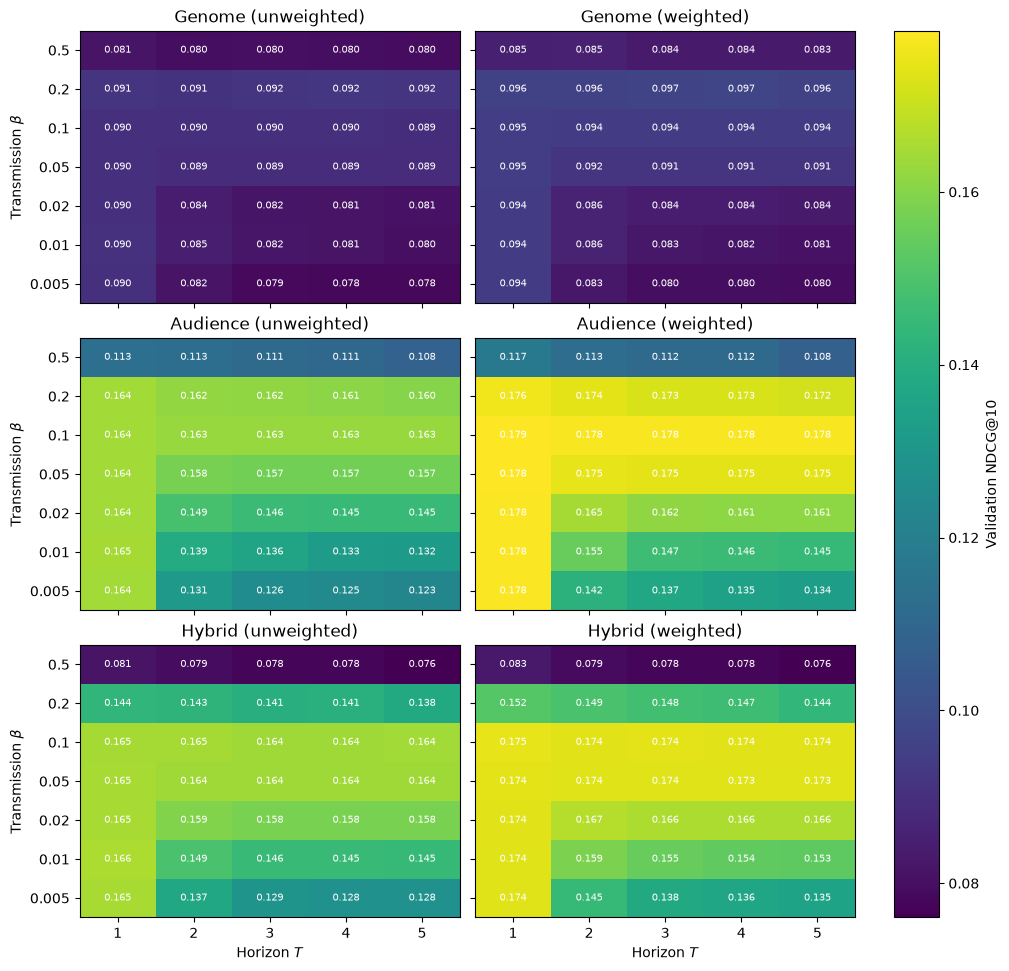

In [21]:
vmin, vmax = tuning["ndcg"].min(), tuning["ndcg"].max()

fig, axes = plt.subplots(
    len(NETWORK_MATRICES), len(WEIGHTINGS),
    figsize=(10, 3.2 * len(NETWORK_MATRICES)), sharex=True, sharey=True,
    constrained_layout=True,
)

for r, name in enumerate(NETWORK_MATRICES):
    for c, weighted in enumerate(WEIGHTINGS):
        ax = axes[r, c]
        grid = (
            tuning[(tuning["network"] == name) & (tuning["weighted"] == weighted)]
            .pivot(index="beta", columns="T", values="ndcg")
        )
        image = ax.imshow(grid.to_numpy(), origin="lower", aspect="auto", vmin=vmin, vmax=vmax)

        for (row, col), value in np.ndenumerate(grid.to_numpy()):
            ax.text(col, row, f"{value:.3f}", ha="center", va="center", fontsize=7, color="white")

        ax.set_xticks(range(len(grid.columns)), grid.columns)
        ax.set_yticks(range(len(grid.index)), grid.index)
        ax.set_title(f"{name} ({'weighted' if weighted else 'unweighted'})")

        if r == len(NETWORK_MATRICES) - 1:
            ax.set_xlabel("Horizon $T$")
        if c == 0:
            ax.set_ylabel(r"Transmission $\beta$")

fig.colorbar(image, ax=axes, label=f"Validation NDCG@{PRIMARY_K}")
plt.show()

# Final comparison on the test users

## Scores for every method

Baselines:
* **Random:** a random ranking of the unseen movies (the floor).
* **Popularity:** movies ranked by their number of positive ratings among the *network* users.
* **1-hop similarity vote:** the sum of the similarity weights between a candidate and the user's seeds in one network (infection with $T = 1$ and small $\beta$, without any simulation).

The infection-based methods use the setting selected on the validation users and many more runs than during tuning.

In [22]:
test = eval_sets["test"]
rng = np.random.default_rng(SEED)

method_scores = {
    "Random": rng.random(test.seeds.shape),
    "Popularity": np.tile(network_positive_counts.astype(float), (len(test.user_ids), 1)),
    "Genome 1-hop vote": test.seeds.astype(float) @ W_genome,
    "Audience 1-hop vote": test.seeds.astype(float) @ W_user,
}

for name, matrices in NETWORK_MATRICES.items():
    setting = best_settings[name]
    exposure = make_exposure(matrices, setting["beta"], bool(setting["weighted"]))
    horizon = int(setting["T"])
    scores, _ = simulate_si(exposure, test.seeds, horizon, TEST_RUNS, np.random.default_rng(SEED))
    method_scores[f"{name} infection"] = scores[horizon - 1]

top_lists = {
    name: rank_top_k(scores, test.seen, max(KS)) for name, scores in method_scores.items()
}

per_user = {
    (name, k): user_metrics(top, test.targets, k)
    for name, top in top_lists.items()
    for k in KS
}

In [23]:
rows = []

for (name, k), metrics in per_user.items():
    low, high = bootstrap_ci(metrics["ndcg"])
    rows.append({
        "method": name,
        "K": k,
        "precision": metrics["precision"].mean(),
        "recall": metrics["recall"].mean(),
        "hit rate": metrics["hit_rate"].mean(),
        "NDCG": metrics["ndcg"].mean(),
        "NDCG 95% CI low": low,
        "NDCG 95% CI high": high,
    })

results = pd.DataFrame(rows)

for k in KS:
    print(f"Top-{k} recommendations ({len(test.user_ids):,} test users)")
    display(results[results["K"] == k].drop(columns="K").set_index("method").round(4))

Top-10 recommendations (4,007 test users)


,precision,recall,hit rate,NDCG,NDCG 95% CI low,NDCG 95% CI high
method,,,,,,
Random,0.0371,0.0247,0.2765,0.0391,0.0366,0.0415
Popularity,0.1000,0.0740,0.4906,0.1143,0.1093,0.1194
Genome 1-hop vote,0.0867,0.0660,0.4996,0.0973,0.0932,0.1014
Audience 1-hop vote,0.1487,0.1220,0.6509,0.1783,0.1718,0.1843
Genome infection,0.0873,0.0664,0.5009,0.0977,0.0936,0.1020
Audience infection,0.1488,0.1221,0.6514,0.1783,0.1718,0.1844
Hybrid infection,0.1504,0.1222,0.6718,0.1777,0.1716,0.1836


Top-20 recommendations (4,007 test users)


,precision,recall,hit rate,NDCG,NDCG 95% CI low,NDCG 95% CI high
method,,,,,,
Random,0.0371,0.0497,0.4352,0.0469,0.0446,0.0491
Popularity,0.0906,0.1309,0.6469,0.1278,0.1233,0.1324
Genome 1-hop vote,0.0838,0.1262,0.6738,0.1164,0.1124,0.1204
Audience 1-hop vote,0.1272,0.2010,0.7959,0.1959,0.1902,0.2015
Genome infection,0.0840,0.1262,0.6736,0.1167,0.1126,0.1206
Audience infection,0.1275,0.2014,0.7961,0.1962,0.1906,0.2018
Hybrid infection,0.1275,0.2002,0.7994,0.1948,0.1894,0.2002


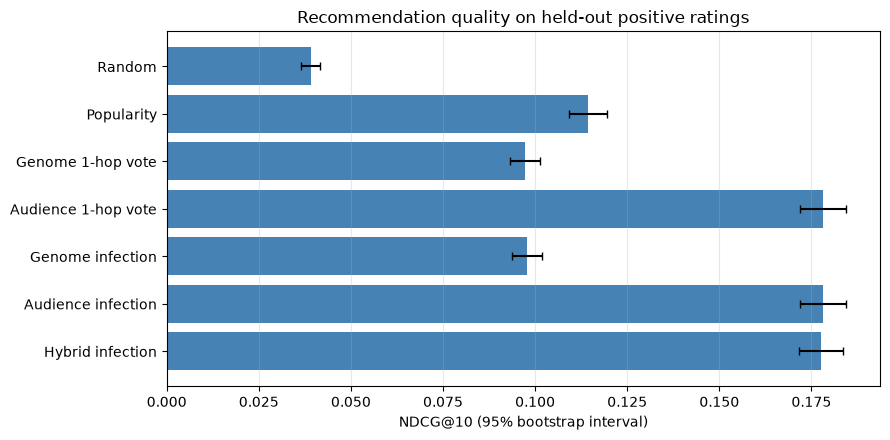

In [24]:
primary = results[results["K"] == PRIMARY_K].set_index("method")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(
    primary.index,
    primary["NDCG"],
    xerr=[primary["NDCG"] - primary["NDCG 95% CI low"], primary["NDCG 95% CI high"] - primary["NDCG"]],
    color="steelblue",
    capsize=3,
)
ax.invert_yaxis()
ax.set(xlabel=f"NDCG@{PRIMARY_K} (95% bootstrap interval)", title="Recommendation quality on held-out positive ratings")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Is the difference between the approaches reliable?

Both approaches are evaluated on the same users, so we compare them user by user. The table shows the mean paired difference in NDCG@10 with a bootstrap interval over users, and the share of users for which each method wins.

In [25]:
def paired_comparison(name_a, name_b, k=PRIMARY_K):
    difference = per_user[(name_a, k)]["ndcg"].to_numpy() - per_user[(name_b, k)]["ndcg"].to_numpy()
    low, high = bootstrap_ci(difference)

    return {
        "comparison (A − B)": f"{name_a} − {name_b}",
        "mean NDCG difference": difference.mean(),
        "95% CI low": low,
        "95% CI high": high,
        "A better (% users)": 100 * (difference > 0).mean(),
        "B better (% users)": 100 * (difference < 0).mean(),
        "tie (% users)": 100 * (difference == 0).mean(),
    }


display(pd.DataFrame([
    paired_comparison("Genome infection", "Audience infection"),
    paired_comparison("Hybrid infection", "Genome infection"),
    paired_comparison("Hybrid infection", "Audience infection"),
    paired_comparison("Genome infection", "Genome 1-hop vote"),
    paired_comparison("Audience infection", "Audience 1-hop vote"),
]).set_index("comparison (A − B)").round(4))

,mean NDCG difference,95% CI low,95% CI high,A better (% users),B better (% users),tie (% users)
comparison (A − B),,,,,,
Genome infection − Audience infection,-0.0806,-0.0863,-0.0751,21.8617,52.6828,25.4555
Hybrid infection − Genome infection,0.0800,0.0753,0.0847,54.4547,16.3464,29.1989
Hybrid infection − Audience infection,-0.0005,-0.0039,0.0027,35.9371,33.9406,30.1223
Genome infection − Genome 1-hop vote,0.0004,-0.0007,0.0014,7.7864,6.4387,85.7749
Audience infection − Audience 1-hop vote,0.0000,-0.0004,0.0005,8.5351,6.9878,84.4772


## Beyond accuracy

Accuracy alone may hide that one approach merely recommends the same blockbusters to everybody. We therefore also report the **catalogue coverage** (share of the 500 movies that appears in at least one top-10 list), the **popularity** of the recommendations (mean popularity percentile among the network users; 1 corresponds to the most positively rated movie), and the **agreement** between the genome and the audience lists (mean Jaccard similarity of the top-10 lists per user).

In [26]:
popularity_percentile = pd.Series(network_positive_counts).rank(pct=True).to_numpy()

rows = []

for name, top in top_lists.items():
    recommended = top[:, :PRIMARY_K]
    rows.append({
        "method": name,
        f"catalogue coverage@{PRIMARY_K}": len(np.unique(recommended)) / N_MOVIES,
        "mean popularity percentile": popularity_percentile[recommended].mean(),
    })

display(pd.DataFrame(rows).set_index("method").round(3))


def mean_list_jaccard(name_a, name_b, k=PRIMARY_K):
    scores = []
    for a, b in zip(top_lists[name_a][:, :k], top_lists[name_b][:, :k]):
        a, b = set(a), set(b)
        scores.append(len(a & b) / len(a | b))
    return np.mean(scores)


print(f"Mean Jaccard similarity of top-{PRIMARY_K} lists")
print(f"  Genome vs Audience infection:  {mean_list_jaccard('Genome infection', 'Audience infection'):.3f}")
print(f"  Genome infection vs Hybrid:    {mean_list_jaccard('Genome infection', 'Hybrid infection'):.3f}")
print(f"  Audience infection vs Hybrid:  {mean_list_jaccard('Audience infection', 'Hybrid infection'):.3f}")

,catalogue coverage@10,mean popularity percentile
method,,
Random,1.000,0.472
Popularity,0.238,0.975
Genome 1-hop vote,0.700,0.690
Audience 1-hop vote,0.454,0.907
Genome infection,0.704,0.690
Audience infection,0.452,0.908
Hybrid infection,0.538,0.892


Mean Jaccard similarity of top-10 lists
  Genome vs Audience infection:  0.090
  Genome infection vs Hybrid:    0.223
  Audience infection vs Hybrid:  0.462


## Dependence on the amount of history

The audience network leaves many movies without links (see the isolated movies above), while the genome network connects almost every movie. We therefore check how quality depends on the number of seeds, by splitting the test users into three equally large groups.

In [27]:
n_seeds = test.seeds.sum(axis=1)
bucket = pd.qcut(
    pd.Series(n_seeds).rank(method="first"), 3, labels=["few seeds", "medium", "many seeds"]
)

print(
    pd.Series(n_seeds).groupby(bucket, observed=True).agg(["min", "max"])
    .rename(columns={"min": "fewest seeds", "max": "most seeds"})
    .to_string()
)

display(pd.DataFrame({
    name: per_user[(name, PRIMARY_K)]["ndcg"].groupby(bucket, observed=True).mean()
    for name in top_lists
}).T.round(4))

            fewest seeds  most seeds
few seeds              5          31
medium                31          60
many seeds            60         351


,few seeds,medium,many seeds
Random,0.0180,0.0247,0.0745
Popularity,0.0675,0.0830,0.1924
Genome 1-hop vote,0.0593,0.0815,0.1511
Audience 1-hop vote,0.1316,0.1423,0.2609
Genome infection,0.0596,0.0817,0.1518
Audience infection,0.1317,0.1422,0.2609
Hybrid infection,0.1254,0.1482,0.2596


## Spreading speed

We now compare how quickly the infection spreads through each network at the **same** transmission probability. This is the recommendation counterpart of plotting $E[I(t)]$ with its standard deviation in the assignment. A network in which the infection stalls (for instance because of many isolated movies) cannot recommend those movies at all.

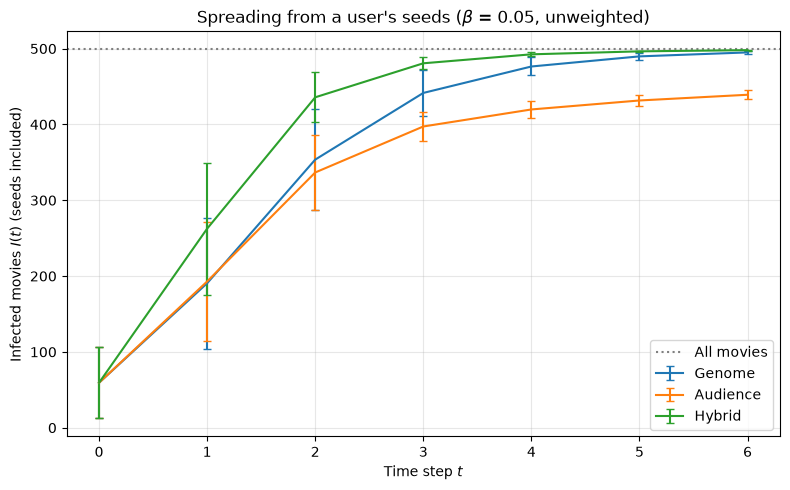

In [28]:
CURVE_BETA = 0.05
CURVE_STEPS = 6
CURVE_USERS = 500

curve_set = test.subset(np.arange(min(CURVE_USERS, len(test.user_ids))))

fig, ax = plt.subplots(figsize=(8, 5))

for name, matrices in NETWORK_MATRICES.items():
    exposure = make_exposure(matrices, CURVE_BETA, weighted=False)
    _, infected = simulate_si(exposure, curve_set.seeds, CURVE_STEPS, 20, np.random.default_rng(SEED))

    steps = np.arange(0, CURVE_STEPS + 1)
    initial = curve_set.seeds.sum(axis=1)
    curves = np.vstack([initial, infected])  # (steps + 1, users)

    ax.errorbar(steps, curves.mean(axis=1), yerr=curves.std(axis=1), capsize=3, label=name)

ax.axhline(N_MOVIES, color="grey", linestyle=":", label="All movies")
ax.set(
    xlabel="Time step $t$",
    ylabel="Infected movies $I(t)$ (seeds included)",
    title=rf"Spreading from a user's seeds ($\beta$ = {CURVE_BETA}, unweighted)",
)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## An example user

A qualitative look at one test user: some of the movies they liked in the history, the movies they went on to like (the targets), and what each infection-based method recommends (✓ marks a target).

In [29]:
example = int(np.random.default_rng(SEED).integers(len(test.user_ids)))

liked = np.flatnonzero(test.seeds[example])
future = set(np.flatnonzero(test.targets[example]))

print(f"User {test.user_ids[example]}: {len(liked)} seeds, {len(future)} held-out positives")
print("\nSome liked movies in the history:")
for movie in np.random.default_rng(SEED).choice(liked, size=min(8, len(liked)), replace=False):
    print(f"  {movie_titles[movie]}")

print("\nHeld-out positives:")
for movie in sorted(future)[:8]:
    print(f"  {movie_titles[movie]}")

for name in ["Genome infection", "Audience infection", "Hybrid infection"]:
    print(f"\n{name}: top 5")
    for movie in top_lists[name][example, :5]:
        print(f"  {'✓' if movie in future else ' '} {movie_titles[movie]}")

User 31080: 50 seeds, 13 held-out positives

Some liked movies in the history:
  Sleepless in Seattle (1993)
  Inside Out (2015)
  Illusionist, The (2006)
  Monsters, Inc. (2001)
  King's Speech, The (2010)
  Big (1988)
  Four Weddings and a Funeral (1994)
  City of God (Cidade de Deus) (2002)

Held-out positives:
  Léon: The Professional (a.k.a. The Professional) (Léon) (1994)
  Shining, The (1980)
  Groundhog Day (1993)
  Fifth Element, The (1997)
  Memento (2000)
  Bourne Identity, The (2002)
  Bourne Supremacy, The (2004)
  Shaun of the Dead (2004)

Genome infection: top 5
    (500) Days of Summer (2009)
    Stand by Me (1986)
    Butch Cassidy and the Sundance Kid (1969)
    As Good as It Gets (1997)
    It's a Wonderful Life (1946)

Audience infection: top 5
    Lord of the Rings: The Fellowship of the Ring, The (2001)
    Lord of the Rings: The Return of the King, The (2003)
    Lord of the Rings: The Two Towers, The (2002)
    Catch Me If You Can (2002)
    Beautiful Mind, A (2

# Sensitivity to the network density

The community analysis in Part 2 used 15% and checked other densities for stability. Here, we repeat the whole procedure (rebuild the audience network, tune on validation users, evaluate on test users) for all four saved densities. This takes several times as long as the main analysis; set `RUN_DENSITY_SENSITIVITY = False` to skip it.

,density,network,beta,T,weighted,NDCG@10,recall@10
0,5,Genome,0.20,1,True,0.1103,0.0757
1,5,Audience,0.20,5,True,0.1747,0.1173
2,5,Hybrid,0.20,4,True,0.1779,0.1212
3,10,Genome,0.20,1,True,0.1026,0.0706
4,10,Audience,0.05,1,True,0.1770,0.1192
5,10,Hybrid,0.10,2,True,0.1793,0.1221
6,15,Genome,0.20,4,True,0.0977,0.0664
7,15,Audience,0.10,1,True,0.1783,0.1221
8,15,Hybrid,0.10,1,True,0.1777,0.1222
9,20,Genome,0.20,5,True,0.0975,0.0666


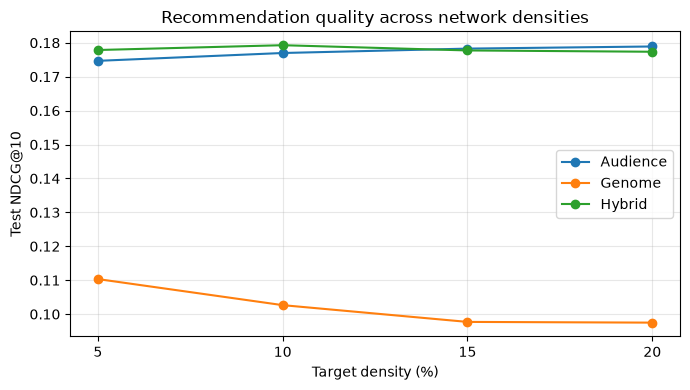

In [30]:
RUN_DENSITY_SENSITIVITY = True
SENSITIVITY_DENSITIES = [5, 10, 15, 20]


def run_density(density_pct):
    W_g = weight_matrix(load_saved_graph("genome", density_pct))
    W_u = build_audience_matrix(int((W_g > 0).sum() // 2))
    networks = {"Genome": [W_g], "Audience": [W_u], "Hybrid": [W_g, W_u]}

    rows = []

    for name, matrices in networks.items():
        tuned = tune_network(matrices, eval_sets["validation"])
        setting = tuned.sort_values("ndcg", ascending=False).iloc[0]

        exposure = make_exposure(matrices, setting["beta"], bool(setting["weighted"]))
        horizon = int(setting["T"])
        scores, _ = simulate_si(exposure, test.seeds, horizon, TEST_RUNS, np.random.default_rng(SEED))

        metrics = user_metrics(rank_top_k(scores[horizon - 1], test.seen, PRIMARY_K), test.targets, PRIMARY_K)
        rows.append({
            "density": density_pct,
            "network": name,
            "beta": setting["beta"],
            "T": horizon,
            "weighted": bool(setting["weighted"]),
            f"NDCG@{PRIMARY_K}": metrics["ndcg"].mean(),
            f"recall@{PRIMARY_K}": metrics["recall"].mean(),
        })

    return rows


if RUN_DENSITY_SENSITIVITY:
    density_results = pd.DataFrame(
        [row for density in SENSITIVITY_DENSITIES for row in run_density(density)]
    )
    display(density_results.round(4))

    fig, ax = plt.subplots(figsize=(7, 4))
    for name, group in density_results.groupby("network"):
        ax.plot(group["density"], group[f"NDCG@{PRIMARY_K}"], marker="o", label=name)

    ax.set(xlabel="Target density (%)", ylabel=f"Test NDCG@{PRIMARY_K}",
           title="Recommendation quality across network densities")
    ax.set_xticks(SENSITIVITY_DENSITIES)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Interpretation

**Audience vs content.** The similar-viewer (audience) approach is clearly better. At K = 10 it gets an NDCG of 0.178 against 0.098 for the genome approach, and a recall of 0.122 against 0.066. The paired difference is -0.081 with a 95% CI of [-0.086, -0.075], and audience wins for 53% of the users against 22% for genome. The genome approach is even a bit below plain popularity (0.114), while audience is well above it. K = 20 shows the same picture.

**Does the infection model help?** Not really. Infection and the 1-hop vote give basically the same results (NDCG difference 0.0000 for audience and 0.0004 for genome, both CIs include 0). Tuning picked T = 1 for audience and hybrid, and for genome T = 4 gave only a tiny gain. The networks are dense with short paths, so everything is reached after one step and more steps add nothing. In this setup the infection model is a neighbourhood vote.

**Hybrid.** Combining both networks does not improve on audience alone (0.1777 vs 0.1783, CI of the difference includes 0). It does give a higher hit rate (0.67 vs 0.65) and more coverage (0.54 vs 0.45). The genome and audience lists hardly overlap (Jaccard 0.09), so they recommend very different movies, but the genome ones are right less often. This fits the limited edge overlap from Part 1.

**Popularity.** Audience recommendations are mostly popular movies (mean popularity percentile 0.91, only 45% of the catalogue ever recommended), while genome ones are more spread out (0.69, 70% of the catalogue). So genome is more diverse, but audience is more accurate, and part of its advantage is probably popularity.

**Cold start.** Audience is better in all three groups of users, also with few seeds (0.132 vs 0.059), so the 27 isolated movies do not hurt much. All methods do better for users with more history.

**Robustness.** Over densities of 5-20% audience stays at 0.175-0.179 and genome at 0.098-0.110 (it is slightly better on the sparsest network). Hybrid is about equal to audience everywhere. The weighted version was selected every time, so the similarity strength matters. The conclusions do not depend on the density.

## Limitations

* The 500 most-rated movies make this easier and more popularity-driven than recommending from the whole catalogue, which probably favours audience.
* "Liked" is a rating of at least 3.5. Held-out movies that were not rated count as irrelevant, so the absolute scores are low.
* Only users with at least 30 ratings are evaluated, so the results may not hold for casual users.
* Ratings given in the same second are ordered arbitrarily, so the history/future split is not exact.